#### Baselines - Random Forest and XGBoost

Horizons: 1h, 24h and 168h ahead (direct approach, one model per horizon).
Also a seasonal naive forecast (same hour last week) as a simple reference.

- hyperparameters tuned with Optuna on the validation set, same number of trials for both models
- final models trained on train with 3 seeds, scored on test
- predictions saved in results/ for the evaluation notebook

In [1]:
import os
import json
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

os.makedirs("../figures", exist_ok=True)

In [2]:
HORIZONS = [1, 24, 168]
SEEDS = [0, 1, 2]
N_TRIALS = 20

os.makedirs("../results/predictions", exist_ok=True)

##### Features

Index = the hour we are predicting (target time). For horizon h the forecast is made h hours before,
so every load feature has to be shifted by at least h.

- lag_h ... lag_h+5: last 6 known hours
- lag_24, 48, 168, 336: same hour 1/2 days and 1/2 weeks before (only the ones >= h)
- rolling mean of the last 24h / 168h known at forecast time
- calendar features of the target hour

In [3]:
def make_features(df, h):
    X = pd.DataFrame(index=df.index)

    lags = [h + k for k in range(6)] + [m for m in [24, 48, 168, 336] if m >= h]
    for s in sorted(set(lags)):
        X[f"lag_{s}"] = df["load"].shift(s)

    X["roll_mean_24"] = df["load"].shift(h).rolling(24).mean()
    X["roll_mean_168"] = df["load"].shift(h).rolling(168).mean()

    for c in ["hour", "dayofweek", "month", "dayofyear", "weekend", "holiday"]:
        X[c] = df[c]

    X = X.dropna()
    y = df["load"].loc[X.index]
    return X, y

In [4]:
def load_data(name):
    train = pd.read_parquet(f"../data/processed/{name}_train.parquet")
    val = pd.read_parquet(f"../data/processed/{name}_val.parquet")
    test = pd.read_parquet(f"../data/processed/{name}_test.parquet")
    return train, val, test


def get_splits(name, h):
    train, val, test = load_data(name)
    # features are made on the full series so the first val/test rows can use the last known values
    X, y = make_features(pd.concat([train, val, test]), h)
    tr = X.index <= train.index.max()
    va = (X.index >= val.index.min()) & (X.index <= val.index.max())
    te = X.index >= test.index.min()
    return X[tr], y[tr], X[va], y[va], X[te], y[te]


def scores(y, pred):
    return {
        "rmse": np.sqrt(mean_squared_error(y, pred)),
        "mae": mean_absolute_error(y, pred),
        "mape": mean_absolute_percentage_error(y, pred) * 100,
        "r2": r2_score(y, pred),
    }

In [5]:
X_tr, y_tr, X_va, y_va, X_te, y_te = get_splits("pjme", 24)
print(X_tr.shape, X_va.shape, X_te.shape)
X_tr.head()

(101438, 17) (21809, 17) (21809, 17)


,lag_24,lag_25,lag_26,lag_27,lag_28,lag_29,lag_48,lag_168,lag_336,roll_mean_24,roll_mean_168,hour,dayofweek,month,dayofyear,weekend,holiday
Datetime,,,,,,,,,,,,,,,,,
2002-01-15 01:00:00,26059.0,27659.0,29545.0,31594.0,32851.0,33337.0,25052.0,29445.0,30393.0,28130.458333,31478.571429,1,1,1,15,0,0
2002-01-15 02:00:00,25487.0,26059.0,27659.0,29545.0,31594.0,32851.0,24007.0,28670.0,29265.0,28192.125000,31475.660714,2,1,1,15,0,0
2002-01-15 03:00:00,25363.0,25487.0,26059.0,27659.0,29545.0,31594.0,23441.0,28375.0,28357.0,28272.208333,31474.005952,3,1,1,15,0,0
2002-01-15 04:00:00,25436.0,25363.0,25487.0,26059.0,27659.0,29545.0,23129.0,28542.0,27899.0,28368.333333,31472.636905,4,1,1,15,0,0
2002-01-15 05:00:00,26117.0,25436.0,25363.0,25487.0,26059.0,27659.0,23244.0,29261.0,28057.0,28488.041667,31471.380952,5,1,1,15,0,0


##### Tuning

In [6]:
def tune_rf(X_tr, y_tr, X_va, y_va):
    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 400, step=50),
            "max_depth": trial.suggest_int("max_depth", 5, 30),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
            "max_features": trial.suggest_categorical("max_features", [0.3, 0.5, 0.8, 1.0]),
        }
        # max_samples=0.5 to keep it fast on the PJME data
        model = RandomForestRegressor(**params, max_samples=0.5, n_jobs=-1, random_state=0)
        model.fit(X_tr, y_tr)
        return np.sqrt(mean_squared_error(y_va, model.predict(X_va)))

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS)
    return study.best_params, study.best_value


def tune_xgb(X_tr, y_tr, X_va, y_va):
    def objective(trial):
        params = {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        }
        model = xgb.XGBRegressor(**params, n_estimators=2000, early_stopping_rounds=50,
                                 tree_method="hist", n_jobs=-1, random_state=0)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        trial.set_user_attr("n_estimators", model.best_iteration + 1)
        return np.sqrt(mean_squared_error(y_va, model.predict(X_va)))

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS)
    params = study.best_params
    params["n_estimators"] = study.best_trial.user_attrs["n_estimators"]
    return params, study.best_value

##### Run everything

Takes a while (RF on PJME is the slow part).

In [7]:
all_scores = []
best_params = {}
models_24 = {}

for name in ["pjme", "uci"]:
    for h in HORIZONS:
        start = time.time()
        X_tr, y_tr, X_va, y_va, X_te, y_te = get_splits(name, h)
        preds = {}

        # seasonal naive - same hour one week before (known for all horizons up to 168)
        preds["naive"] = {"seed_0": X_te["lag_168"].values}

        rf_params, rf_val = tune_rf(X_tr, y_tr, X_va, y_va)
        xgb_params, xgb_val = tune_xgb(X_tr, y_tr, X_va, y_va)
        best_params[f"{name}_h{h}"] = {"rf": rf_params, "xgb": xgb_params}

        preds["rf"], preds["xgb"] = {}, {}
        for seed in SEEDS:
            rf = RandomForestRegressor(**rf_params, max_samples=0.5, n_jobs=-1, random_state=seed)
            rf.fit(X_tr, y_tr)
            preds["rf"][f"seed_{seed}"] = rf.predict(X_te)

            xg = xgb.XGBRegressor(**xgb_params, tree_method="hist", n_jobs=-1, random_state=seed)
            xg.fit(X_tr, y_tr)
            preds["xgb"][f"seed_{seed}"] = xg.predict(X_te)

        if h == 24:
            models_24[name] = {"rf": rf, "xgb": xg, "columns": X_tr.columns}

        for model, p in preds.items():
            out = pd.DataFrame(p, index=X_te.index)
            out.insert(0, "actual", y_te.values)
            out.to_parquet(f"../results/predictions/{name}_{model}_h{h}.parquet")
            for seed_col in p:
                all_scores.append({"dataset": name, "model": model, "horizon": h, "seed": seed_col,
                                   **scores(y_te, p[seed_col])})

        print(f"{name} h={h}: val rmse rf={rf_val:.3f} xgb={xgb_val:.3f}  ({time.time() - start:.0f}s)")

pjme h=1: val rmse rf=382.021 xgb=281.627  (504s)


pjme h=24: val rmse rf=2269.154 xgb=2238.620  (328s)


pjme h=168: val rmse rf=3354.868 xgb=3293.704  (167s)


uci h=1: val rmse rf=0.534 xgb=0.524  (109s)


uci h=24: val rmse rf=0.664 xgb=0.655  (64s)


uci h=168: val rmse rf=0.663 xgb=0.654  (53s)


In [8]:
scores_df = pd.DataFrame(all_scores)
scores_df.to_csv("../results/baseline_scores.csv", index=False)

with open("../results/baseline_params.json", "w") as f:
    json.dump(best_params, f, indent=2)

##### Results (test set, mean and std over seeds)

In [9]:
summary = scores_df.groupby(["dataset", "horizon", "model"])[["rmse", "mae", "mape", "r2"]].agg(["mean", "std"])
summary.round(3)

rmse              mae           mape            r2  \
                           mean    std      mean    std    mean    std   mean   
dataset horizon model                                                           
pjme    1       naive  4732.501    NaN  3431.189    NaN  10.689    NaN  0.460   
                rf      394.078  0.235   278.487  0.214   0.893  0.001  0.996   
                xgb     321.808  1.600   232.913  1.680   0.741  0.006  0.998   
        24      naive  4732.501    NaN  3431.189    NaN  10.689    NaN  0.460   
                rf     2473.246  1.414  1813.658  1.335   5.725  0.005  0.852   
                xgb    2449.348  0.346  1808.696  0.711   5.714  0.004  0.855   
        168     naive  4732.501    NaN  3431.189    NaN  10.689    NaN  0.460   
                rf     3690.117  1.979  2788.780  0.985   8.832  0.005  0.672   
                xgb    3686.814  2.308  2780.984  0.893   8.812  0.004  0.672   
uci     1       naive     0.791    NaN     0.554    NaN  76.364    NaN -0.257   
                rf        0.461  0.000     0.317  0.000  42.809  0.047  0.573   
                xgb       0.455  0.000     0.313  0.000  42.599  0.033  0.585   
        24      naive     0.791    NaN     0.554    NaN  76.364    NaN -0.257   
                rf        0.573  0.000     0.421  0.000  62.984  0.049  0.341   
                xgb       0.562  0.001     0.413  0.000  61.743  0.118  0.366   
        168     naive     0.791    NaN     0.554    NaN  76.364    NaN -0.257   
                rf        0.587  0.001     0.435  0.001  65.266  0.254  0.309   
                xgb       0.579  0.001     0.430  0.001  64.238  0.177  0.326   

                              
                         std  
dataset horizon model         
pjme    1       naive    NaN  
                rf     0.000  
                xgb    0.000  
        24      naive    NaN  
                rf     0.000  
                xgb    0.000  
        168     naive    NaN  
                rf     0.000  
                xgb    0.000  
uci     1       naive    NaN  
                rf     0.000  
                xgb    0.001  
        24      naive    NaN  
                rf     0.000  
                xgb    0.002  
        168     naive    NaN  
                rf     0.003  
                xgb    0.001

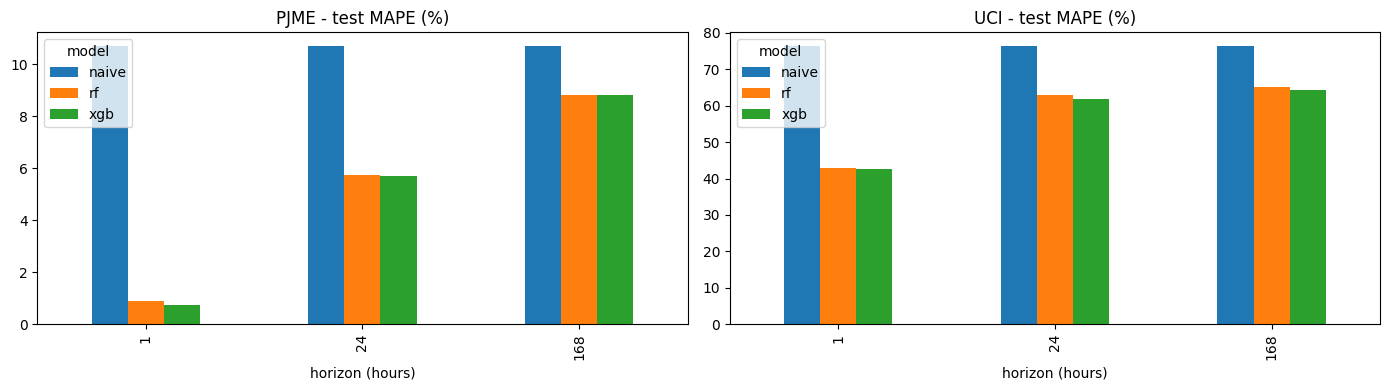

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, name in zip(ax, ["pjme", "uci"]):
    d = scores_df[scores_df["dataset"] == name].groupby(["horizon", "model"])["mape"].mean().unstack()
    d.plot(kind="bar", ax=a)
    a.set_title(name.upper() + " - test MAPE (%)")
    a.set_xlabel("horizon (hours)")
plt.tight_layout()
plt.savefig("../figures/04_test_mape.png", dpi=150, bbox_inches="tight")
plt.show()

Notes:
- PJME 1h: both models are very accurate (MAPE < 1%), XGBoost a bit better. Error grows a lot with the horizon (~5.7% at 24h, ~8.8% at 168h).
- PJME 24h and 168h: RF and XGBoost are almost the same.
- Both models beat the seasonal naive forecast (10.7%) at every horizon.
- UCI is much harder: R2 only ~0.58 at 1h and ~0.33 at 168h. MAPE is very high (42-65%) because night values are close to zero
  (~0.12-0.3 kW), so small errors give big percentages - RMSE and MAE are more useful for UCI.
- For UCI 24h and 168h are almost the same - after one day there is little extra information from recent hours (matches the low ACF in notebook 03).
- Std over seeds is small for PJME, bigger for UCI (up to ~0.25% MAPE).


##### Feature importance (24h models)

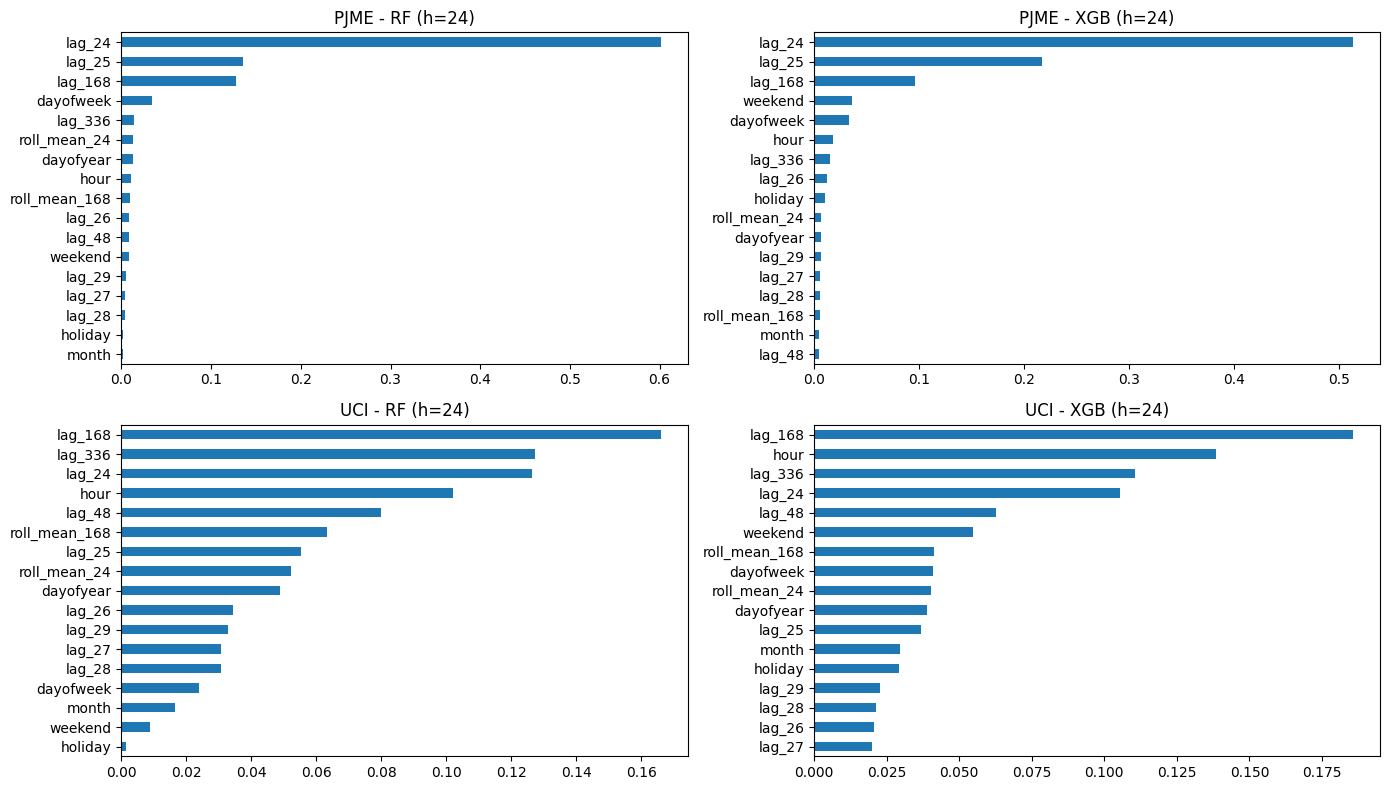

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for i, name in enumerate(["pjme", "uci"]):
    m = models_24[name]
    for j, model in enumerate(["rf", "xgb"]):
        imp = pd.Series(m[model].feature_importances_, index=m["columns"]).sort_values()
        imp.plot(kind="barh", ax=ax[i, j])
        ax[i, j].set_title(f"{name.upper()} - {model.upper()} (h=24)")
plt.tight_layout()
plt.savefig("../figures/04_feature_importance_24h.png", dpi=150, bbox_inches="tight")
plt.show()

##### Forecast vs actual - one test week, 24h ahead

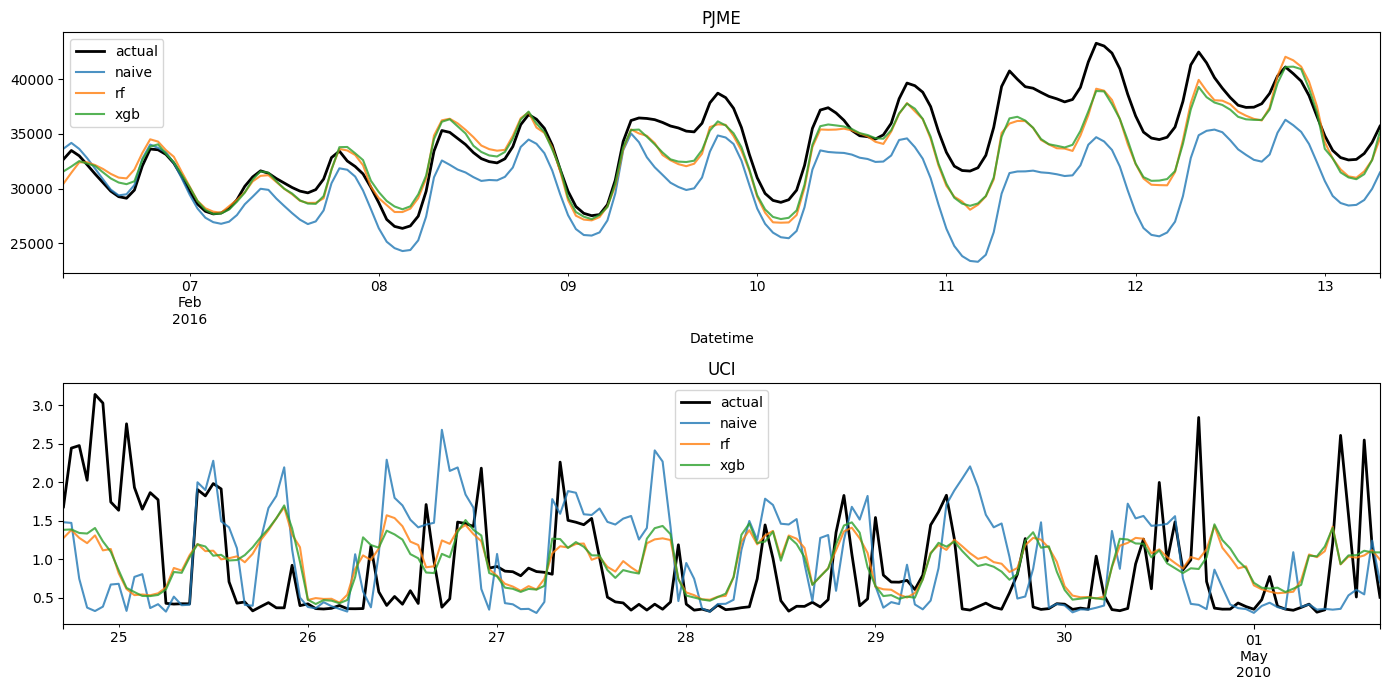

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(14, 7))
for a, name in zip(ax, ["pjme", "uci"]):
    week = slice(None, 24 * 7)
    for model in ["naive", "rf", "xgb"]:
        p = pd.read_parquet(f"../results/predictions/{name}_{model}_h24.parquet")
        if model == "naive":
            p["actual"].iloc[week].plot(ax=a, color="black", lw=2, label="actual")
        p["seed_0"].iloc[week].plot(ax=a, label=model, alpha=0.8)
    a.set_title(name.upper())
    a.legend()
plt.tight_layout()
plt.savefig("../figures/04_forecast_week_24h.png", dpi=150, bbox_inches="tight")
plt.show()